In [1]:
import duckdb
import pandas as pd

pd.set_option("display.float_format", "{:,.2f}".format)
con = duckdb.connect("olist.duckdb")

In [2]:
con.sql("""
    CREATE OR REPLACE VIEW order_summary AS
    WITH items AS (
        SELECT
            order_id,
            COUNT(*)           AS n_items,
            SUM(price)         AS product_value,
            SUM(freight_value) AS freight_value
        FROM order_items
        GROUP BY order_id
    )
    SELECT
        o.order_id,
        c.customer_unique_id,
        c.customer_state,
        o.order_status,
        o.order_purchase_timestamp,
        o.order_delivered_customer_date,
        o.order_estimated_delivery_date,
        i.n_items,
        i.product_value,
        i.freight_value,
        i.product_value + i.freight_value AS order_value,
        r.review_score
    FROM orders o
    JOIN customers c          ON o.customer_id = c.customer_id
    LEFT JOIN items i         ON o.order_id = i.order_id
    LEFT JOIN reviews_clean r ON o.order_id = r.order_id
""")

In [3]:
con.sql("""
    SELECT
        COUNT(*)                 AS total_rows,
        COUNT(DISTINCT order_id) AS unique_orders,
        COUNT(review_score)      AS orders_with_review,
        COUNT(order_value)       AS orders_with_value
    FROM order_summary
""").df()

,total_rows,unique_orders,orders_with_review,orders_with_value
0,99441,99441,98673,98666


In [4]:
monthly = con.sql("""
    SELECT
        DATE_TRUNC('month', order_purchase_timestamp) AS month,
        COUNT(*)         AS orders,
        SUM(order_value) AS revenue,
        AVG(order_value) AS avg_order_value
    FROM order_summary
    WHERE order_status NOT IN ('canceled', 'unavailable')
    GROUP BY month
    ORDER BY month
""").df()

monthly

,month,orders,revenue,avg_order_value
0,2016-09-01,2,279.69,139.85
1,2016-10-01,293,"51,354.52",177.08
2,2016-12-01,1,19.62,19.62
3,2017-01-01,787,"136,943.46",174.01
4,2017-02-01,1718,"283,561.69",165.05
5,2017-03-01,2617,"425,617.96",162.64
6,2017-04-01,2377,"405,848.61",170.74
7,2017-05-01,3640,"582,710.83",160.09
8,2017-06-01,3205,"499,652.24",155.90
9,2017-07-01,3946,"578,753.73",146.67


<Axes: title={'center': 'Monthly orders'}, xlabel='month'>

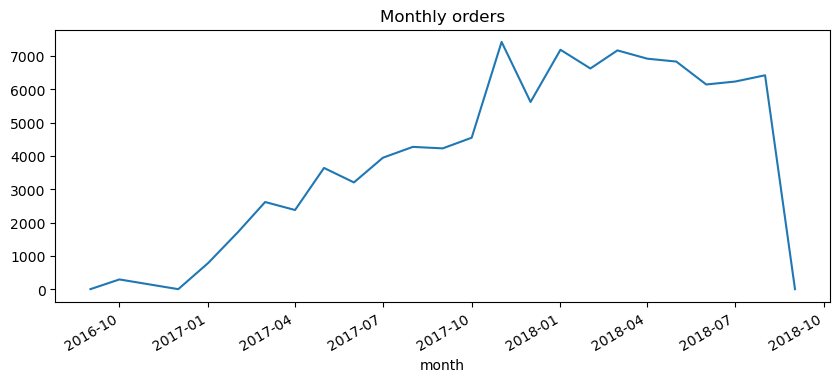

In [5]:
monthly.plot(x="month", y="orders", figsize=(10, 4), title="Monthly orders", legend=False)

In [6]:
con.sql("""
    WITH yearly AS (
        SELECT
            YEAR(order_purchase_timestamp) AS year,
            COUNT(*)                       AS orders,
            SUM(order_value)               AS revenue,
            AVG(order_value)               AS avg_order_value
        FROM order_summary
        WHERE order_status NOT IN ('canceled', 'unavailable')
          AND YEAR(order_purchase_timestamp) IN (2017, 2018)
          AND MONTH(order_purchase_timestamp) <= 8
        GROUP BY year
    )
    SELECT
        *,
        ROUND(100.0 * (revenue - LAG(revenue) OVER (ORDER BY year))
              / LAG(revenue) OVER (ORDER BY year), 1) AS revenue_growth_pct
    FROM yearly
    ORDER BY year
""").df()

,year,orders,revenue,avg_order_value,revenue_growth_pct
0,2017,22562,"3,574,992.04",158.45,NaN
1,2018,53531,"8,593,137.50",160.53,140.40


## Business overview: findings
- Analysis window: Jan 2017 – Aug 2018 (2016 is sparse launch data; Sep 2018 is incomplete)
- Jan–Aug revenue grew 140% YoY (R$3.57M → R$8.59M), driven almost entirely by order volume (+137%); avg order value was flat (~R$160)
- Growth plateaued at ~6–7k orders/month through 2018; Black Friday (Nov 2017) was the peak month
- With 97% one-time buyers, growth has been acquisition-driven → retention is the main untapped lever

In [7]:
con.sql("""
    WITH delivered AS (
        SELECT
            review_score,
            DATE_DIFF('day', order_estimated_delivery_date,
                             order_delivered_customer_date) AS days_late
        FROM order_summary
        WHERE order_status = 'delivered'
          AND order_delivered_customer_date IS NOT NULL
          AND review_score IS NOT NULL
          AND order_purchase_timestamp >= '2017-01-01'
          AND order_purchase_timestamp <  '2018-09-01'
    )
    SELECT
        CASE WHEN days_late > 0 THEN 'Late' ELSE 'On time or early' END AS delivery_status,
        COUNT(*) AS orders,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1)              AS pct_of_orders,
        ROUND(AVG(review_score), 2)                                     AS avg_review,
        ROUND(100.0 * AVG(CASE WHEN review_score = 1 THEN 1 ELSE 0 END), 1) AS pct_one_star
    FROM delivered
    GROUP BY delivery_status
""").df()

,delivery_status,orders,pct_of_orders,avg_review,pct_one_star
0,On time or early,89182,93.30,4.29,6.60
1,Late,6378,6.70,2.27,53.80


In [8]:
lateness = con.sql("""
    WITH delivered AS (
        SELECT
            review_score,
            DATE_DIFF('day', order_estimated_delivery_date,
                             order_delivered_customer_date) AS days_late
        FROM order_summary
        WHERE order_status = 'delivered'
          AND order_delivered_customer_date IS NOT NULL
          AND review_score IS NOT NULL
          AND order_purchase_timestamp >= '2017-01-01'
          AND order_purchase_timestamp <  '2018-09-01'
    )
    SELECT
        CASE
            WHEN days_late <= -14 THEN '1. 14+ days early'
            WHEN days_late <= -7  THEN '2. 7-13 days early'
            WHEN days_late <= 0   THEN '3. 0-6 days early'
            WHEN days_late <= 3   THEN '4. 1-3 days late'
            WHEN days_late <= 7   THEN '5. 4-7 days late'
            WHEN days_late <= 14  THEN '6. 8-14 days late'
            ELSE                       '7. 15+ days late'
        END AS lateness,
        COUNT(*)                                                         AS orders,
        ROUND(AVG(review_score), 2)                                      AS avg_review,
        ROUND(100.0 * AVG(CASE WHEN review_score = 1 THEN 1 ELSE 0 END), 1) AS pct_one_star
    FROM delivered
    GROUP BY lateness
    ORDER BY lateness
""").df()

lateness

,lateness,orders,avg_review,pct_one_star
0,1. 14+ days early,41614,4.33,6.50
1,2. 7-13 days early,33873,4.30,6.40
2,3. 0-6 days early,13695,4.17,7.30
3,4. 1-3 days late,1851,3.29,25.10
4,5. 4-7 days late,1748,2.10,58.60
5,6. 8-14 days late,1446,1.67,70.60
6,7. 15+ days late,1333,1.72,69.00


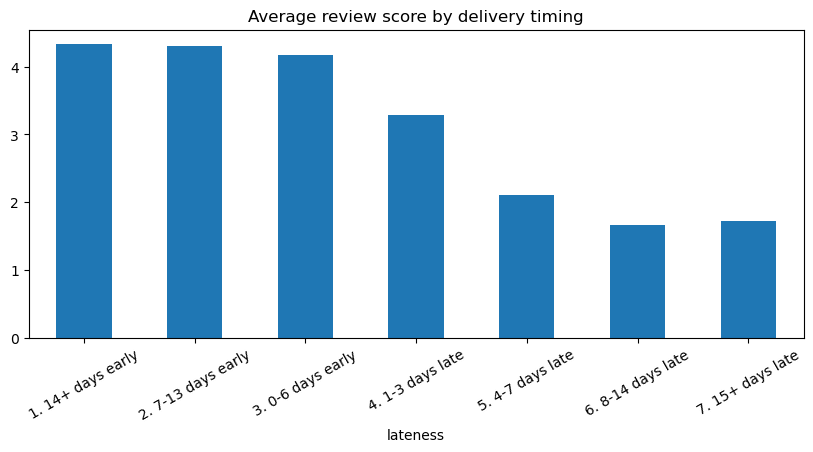

In [9]:
lateness.plot(x="lateness", y="avg_review", kind="bar", figsize=(10, 4),
              title="Average review score by delivery timing", legend=False, rot=30);

## Delivery vs. reviews: findings
- 6.7% of orders arrive late; they average 2.27 stars vs. 4.29 for on-time orders
- Late orders are 8x more likely to get a 1-star review (53.8% vs. 6.6%) and account for ~37% of all 1-star reviews
- Early delivery earns little extra credit; reviews drop sharply as soon as the estimate is missed and bottom out after ~1 week late
- Takeaway: customers judge against the promised date, so keeping the estimate matters more than raw speed

In [10]:
con.sql("""
    WITH delivered AS (
        SELECT
            customer_state,
            DATE_DIFF('day', order_purchase_timestamp,
                             order_delivered_customer_date) AS delivery_days,
            CASE WHEN order_delivered_customer_date > order_estimated_delivery_date
                 THEN 1 ELSE 0 END                          AS is_late
        FROM order_summary
        WHERE order_status = 'delivered'
          AND order_delivered_customer_date IS NOT NULL
          AND order_purchase_timestamp >= '2017-01-01'
          AND order_purchase_timestamp <  '2018-09-01'
    )
    SELECT
        customer_state,
        COUNT(*)                         AS orders,
        ROUND(AVG(delivery_days), 1)     AS avg_delivery_days,
        ROUND(100.0 * AVG(is_late), 1)   AS pct_late
    FROM delivered
    GROUP BY customer_state
    HAVING COUNT(*) >= 500
    ORDER BY pct_late DESC
""").df()

,customer_state,orders,avg_delivery_days,pct_late
0,MA,713,21.50,19.60
1,CE,1273,21.20,15.40
2,BA,3253,19.30,14.00
3,RJ,12310,15.20,13.50
4,PA,942,23.70,12.40
5,ES,1992,15.70,12.20
6,MS,701,15.50,11.60
7,PB,516,20.40,11.00
8,PE,1587,18.40,10.80
9,SC,3537,14.90,9.80


In [11]:
con.sql("""
    CREATE OR REPLACE VIEW order_summary AS
    WITH items AS (
        SELECT
            order_id,
            COUNT(*)           AS n_items,
            SUM(price)         AS product_value,
            SUM(freight_value) AS freight_value
        FROM order_items
        GROUP BY order_id
    )
    SELECT
        o.order_id,
        c.customer_unique_id,
        c.customer_state,
        o.order_status,
        o.order_purchase_timestamp,
        o.order_delivered_customer_date,
        o.order_estimated_delivery_date,
        DATE_DIFF('day', o.order_purchase_timestamp,
                         o.order_delivered_customer_date)      AS delivery_days,
        DATE_DIFF('day', o.order_estimated_delivery_date,
                         o.order_delivered_customer_date)      AS days_late,
        CASE
            WHEN o.order_delivered_customer_date IS NULL THEN NULL
            WHEN DATE_DIFF('day', o.order_estimated_delivery_date,
                                  o.order_delivered_customer_date) > 0 THEN 1
            ELSE 0
        END                                                    AS is_late,
        i.n_items,
        i.product_value,
        i.freight_value,
        i.product_value + i.freight_value                      AS order_value,
        r.review_score
    FROM orders o
    JOIN customers c          ON o.customer_id = c.customer_id
    LEFT JOIN items i         ON o.order_id = i.order_id
    LEFT JOIN reviews_clean r ON o.order_id = r.order_id
""")

In [12]:
con.sql("""
    SELECT
        customer_state,
        COUNT(*)                       AS orders,
        ROUND(AVG(delivery_days), 1)   AS avg_delivery_days,
        ROUND(100.0 * AVG(is_late), 1) AS pct_late
    FROM order_summary
    WHERE order_status = 'delivered'
      AND is_late IS NOT NULL
      AND order_purchase_timestamp >= '2017-01-01'
      AND order_purchase_timestamp <  '2018-09-01'
    GROUP BY customer_state
    HAVING COUNT(*) >= 500
    ORDER BY pct_late DESC
""").df()

,customer_state,orders,avg_delivery_days,pct_late
0,MA,713,21.50,17.50
1,CE,1273,21.20,13.80
2,BA,3253,19.30,12.20
3,RJ,12310,15.20,12.10
4,PA,942,23.70,11.30
5,ES,1992,15.70,10.70
6,PB,516,20.40,10.50
7,MS,701,15.50,9.70
8,PE,1587,18.40,9.60
9,SC,3537,14.90,8.20


## Late deliveries by state: findings
- Late rates are highest in the Northeast/North (MA 17.5%, CE 13.8%, BA 12.2%), where delivery takes 18–24 days
- SP is fastest (8.7 days) with a low late rate (4.5%), but its volume still makes it the largest source of late orders
- RJ combines high volume (12k orders) with a high late rate (12.1%) despite moderate delivery times → highest-impact state to fix
- Long delivery ≠ late: MT averages 18 days but only 6.0% late, because its estimates account for distance

In [13]:
con.sql("""
    WITH ranked AS (
        SELECT
            customer_unique_id,
            order_status,
            order_purchase_timestamp,
            review_score,
            ROW_NUMBER() OVER (
                PARTITION BY customer_unique_id
                ORDER BY order_purchase_timestamp
            ) AS order_num,
            COUNT(*) OVER (PARTITION BY customer_unique_id) AS total_orders
        FROM order_summary
    ),
    first_orders AS (
        SELECT *
        FROM ranked
        WHERE order_num = 1
          AND order_status = 'delivered'
          AND review_score IS NOT NULL
          AND order_purchase_timestamp >= '2017-01-01'
          AND order_purchase_timestamp <  '2018-03-01'
    )
    SELECT
        review_score AS first_order_review,
        COUNT(*)     AS customers,
        ROUND(100.0 * AVG(CASE WHEN total_orders > 1 THEN 1 ELSE 0 END), 2) AS pct_returned
    FROM first_orders
    GROUP BY review_score
    ORDER BY review_score
""").df()

,first_order_review,customers,pct_returned
0,1,5426,3.80
1,2,1761,3.58
2,3,4782,3.89
3,4,11016,3.67
4,5,31799,4.28


## First-order experience vs. repeat purchase: findings
- Return rates are flat across first-order review scores (3.6–4.3%); 1-star vs. 5-star difference is not statistically significant (z ≈ 1.7, p ≈ 0.09)
- First orders limited to Jan 2017–Feb 2018 so every customer had 6+ months to return (avoids censoring)
- Conclusion: delivery drives satisfaction, but not retention; low repeat rates appear structural (likely Olist's marketplace model), so retention needs a separate strategy

In [14]:
con.sql("""
    WITH ranked AS (
        SELECT
            order_id,
            customer_unique_id,
            order_status,
            order_purchase_timestamp,
            ROW_NUMBER() OVER (
                PARTITION BY customer_unique_id
                ORDER BY order_purchase_timestamp
            ) AS order_num,
            COUNT(*) OVER (PARTITION BY customer_unique_id) AS total_orders
        FROM order_summary
    ),
    first_orders AS (
        SELECT *
        FROM ranked
        WHERE order_num = 1
          AND order_status = 'delivered'
          AND order_purchase_timestamp >= '2017-01-01'
          AND order_purchase_timestamp <  '2018-03-01'
    ),
    first_category AS (
        SELECT
            f.customer_unique_id,
            f.total_orders,
            COALESCE(cn.product_category_name_english,
                     p.product_category_name, 'unknown') AS category
        FROM first_orders f
        JOIN order_items oi    ON f.order_id = oi.order_id AND oi.order_item_id = 1
        JOIN products p        ON oi.product_id = p.product_id
        LEFT JOIN category_names cn ON p.product_category_name = cn.product_category_name
    )
    SELECT
        category,
        COUNT(*) AS customers,
        ROUND(100.0 * AVG(CASE WHEN total_orders > 1 THEN 1 ELSE 0 END), 2) AS pct_returned
    FROM first_category
    GROUP BY category
    HAVING COUNT(*) >= 500
    ORDER BY pct_returned DESC
""").df()

,category,customers,pct_returned
0,fashion_bags_accessories,1128,7.18
1,bed_bath_table,5355,6.11
2,furniture_decor,3674,5.93
3,sports_leisure,4483,5.02
4,pet_shop,815,4.66
5,computers_accessories,3757,4.23
6,health_beauty,4297,4.17
7,garden_tools,2298,3.74
8,housewares,2910,3.68
9,perfumery,1945,3.50


In [16]:
con.sql("""
    WITH ranked AS (
        SELECT
            customer_unique_id,
            order_purchase_timestamp,
            ROW_NUMBER() OVER (
                PARTITION BY customer_unique_id
                ORDER BY order_purchase_timestamp
            ) AS order_num,
            LEAD(order_purchase_timestamp) OVER (
                PARTITION BY customer_unique_id
                ORDER BY order_purchase_timestamp
            ) AS next_order_ts
        FROM order_summary
    ),
    gaps AS (
        SELECT DATE_DIFF('day', order_purchase_timestamp, next_order_ts) AS gap_days
        FROM ranked
        WHERE order_num = 1
          AND next_order_ts IS NOT NULL
    )
    SELECT
        CASE
            WHEN gap_days = 0    THEN '1. Same day'
            WHEN gap_days <= 7   THEN '2. 1-7 days'
            WHEN gap_days <= 30  THEN '3. 8-30 days'
            WHEN gap_days <= 90  THEN '4. 31-90 days'
            WHEN gap_days <= 180 THEN '5. 91-180 days'
            ELSE                      '6. 180+ days'
        END AS time_to_second_order,
        COUNT(*) AS customers,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct
    FROM gaps
    GROUP BY time_to_second_order
    ORDER BY time_to_second_order
""").df()

,time_to_second_order,customers,pct
0,1. Same day,897,29.90
1,2. 1-7 days,213,7.10
2,3. 8-30 days,423,14.10
3,4. 31-90 days,526,17.60
4,5. 91-180 days,428,14.30
5,6. 180+ days,510,17.00


In [17]:
con.sql("""
    WITH ranked AS (
        SELECT
            order_id,
            customer_unique_id,
            order_status,
            order_purchase_timestamp,
            ROW_NUMBER() OVER (
                PARTITION BY customer_unique_id
                ORDER BY order_purchase_timestamp
            ) AS order_num,
            MAX(CAST(order_purchase_timestamp AS DATE)) OVER (
                PARTITION BY customer_unique_id
            ) AS last_order_date
        FROM order_summary
    ),
    first_orders AS (
        SELECT
            *,
            CASE WHEN last_order_date > CAST(order_purchase_timestamp AS DATE)
                 THEN 1 ELSE 0 END AS returned
        FROM ranked
        WHERE order_num = 1
          AND order_status = 'delivered'
          AND order_purchase_timestamp >= '2017-01-01'
          AND order_purchase_timestamp <  '2018-03-01'
    ),
    first_category AS (
        SELECT
            f.returned,
            COALESCE(cn.product_category_name_english,
                     p.product_category_name, 'unknown') AS category
        FROM first_orders f
        JOIN order_items oi    ON f.order_id = oi.order_id AND oi.order_item_id = 1
        JOIN products p        ON oi.product_id = p.product_id
        LEFT JOIN category_names cn ON p.product_category_name = cn.product_category_name
    )
    SELECT
        category,
        COUNT(*)                          AS customers,
        ROUND(100.0 * AVG(returned), 2)   AS pct_returned
    FROM first_category
    GROUP BY category
    HAVING COUNT(*) >= 500
    ORDER BY pct_returned DESC
""").df()

,category,customers,pct_returned
0,fashion_bags_accessories,1128,5.05
1,pet_shop,815,4.17
2,bed_bath_table,5354,3.81
3,furniture_decor,3675,3.81
4,sports_leisure,4482,3.50
5,garden_tools,2299,3.22
6,health_beauty,4296,2.84
7,perfumery,1943,2.83
8,baby,1484,2.76
9,housewares,2911,2.75


## Repeat purchase by first-order category: findings
- ~30% of apparent repeat customers placed their second order the same day (multi-seller checkouts split into separate orders) → redefined "returned" as ordering again on a later date
- True repeat rate is ~2.2%, not the 3.1% the raw data suggests
- With the corrected definition, fashion accessories (5.1%), pet supplies (4.2%), and home goods (3.8%) bring customers back most; gifts, games, and office furniture least (~1.7–1.8%)
- Category explains far more variation in repeat purchases than first-order review score
- ~55% of genuine returns happen within 90 days of the first purchase